In [217]:
!pip install adjustText python-dotenv

In [218]:
import os
from dotenv import load_dotenv

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import requests
from adjustText import adjust_text
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [219]:
load_dotenv()
API_KEY = os.getenv("TMDB_API_KEY")
if not API_KEY:
    raise RuntimeError("Set TMDB_API_KEY in .env before running this notebook.")
TRENDING_URL = f'https://api.themoviedb.org/3/trending/movie/week?api_key={API_KEY}'
GENRE_URL = f'https://api.themoviedb.org/3/genre/movie/list?api_key={API_KEY}&language=en'

In [220]:
genre_response = requests.get(GENRE_URL)
trending_response = requests.get(TRENDING_URL)

if genre_response.status_code==200 & trending_response.status_code==200:
  genre_data = genre_response.json()
  trending_data = trending_response.json()
else:
  print("Can't get data!")

genre_map = {g['id']: g['name'] for g in genre_data.get('genres', [])}

In [221]:
extracted_data = []

for movie in trending_data.get('results', []):
  genre_ids = movie.get('genre_ids', [])
  genre_names = [genre_map.get(gid) for gid in genre_ids if gid in genre_map]
  # genre_str = ' '.join(genre_names)
  extracted_data.append({
      'Title': movie.get('title'),
      'Overview': movie.get('overview'),
      'Release_Date': movie.get('release_date'),
      'Popularity': movie.get('popularity'),
      'Genres': genre_names,
  })

In [222]:
data = extracted_data
df = pd.DataFrame(data)

In [223]:
print('=== Data Table FILM TRENDING REAL-TIME FROM TMDB ===')
print(df[['Title', 'Release_Date', 'Popularity', 'Genres']].head())
print('\n' + '=' * 40 + '\n')

=== Data Table FILM TRENDING REAL-TIME FROM TMDB ===
           Title Release_Date  Popularity  \
0         Digger   2026-09-28    215.8388   
1  Resident Evil   2026-09-16    397.2336   
2         Runner   2026-09-07    289.7676   
3         Verity   2026-09-30    143.2506   
4   The Uprising   2026-09-10    171.1571   

                                 Genres  
0                       [Comedy, Drama]  
1  [Horror, Science Fiction, Adventure]  
2                      [Action, Comedy]  
3                   [Mystery, Thriller]  
4                      [History, Drama]  




In [224]:
def dummy_tokenizer(doc):
  return doc

tfidf = TfidfVectorizer(
    tokenizer=dummy_tokenizer,
    preprocessor=lambda x: x,
    lowercase=False
)
tfidf_matrix = tfidf.fit_transform(df['Genres'])
similarity = cosine_similarity(tfidf_matrix, tfidf_matrix)

print('Bentuk Matriks TF-IDF:', tfidf_matrix.shape)
print('Fitur Kategori:', tfidf.get_feature_names_out())

Bentuk Matriks TF-IDF: (20, 14)
Fitur Kategori: ['Action' 'Adventure' 'Animation' 'Comedy' 'Crime' 'Drama' 'Family'
 'Fantasy' 'History' 'Horror' 'Mystery' 'Romance' 'Science Fiction'
 'Thriller']


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


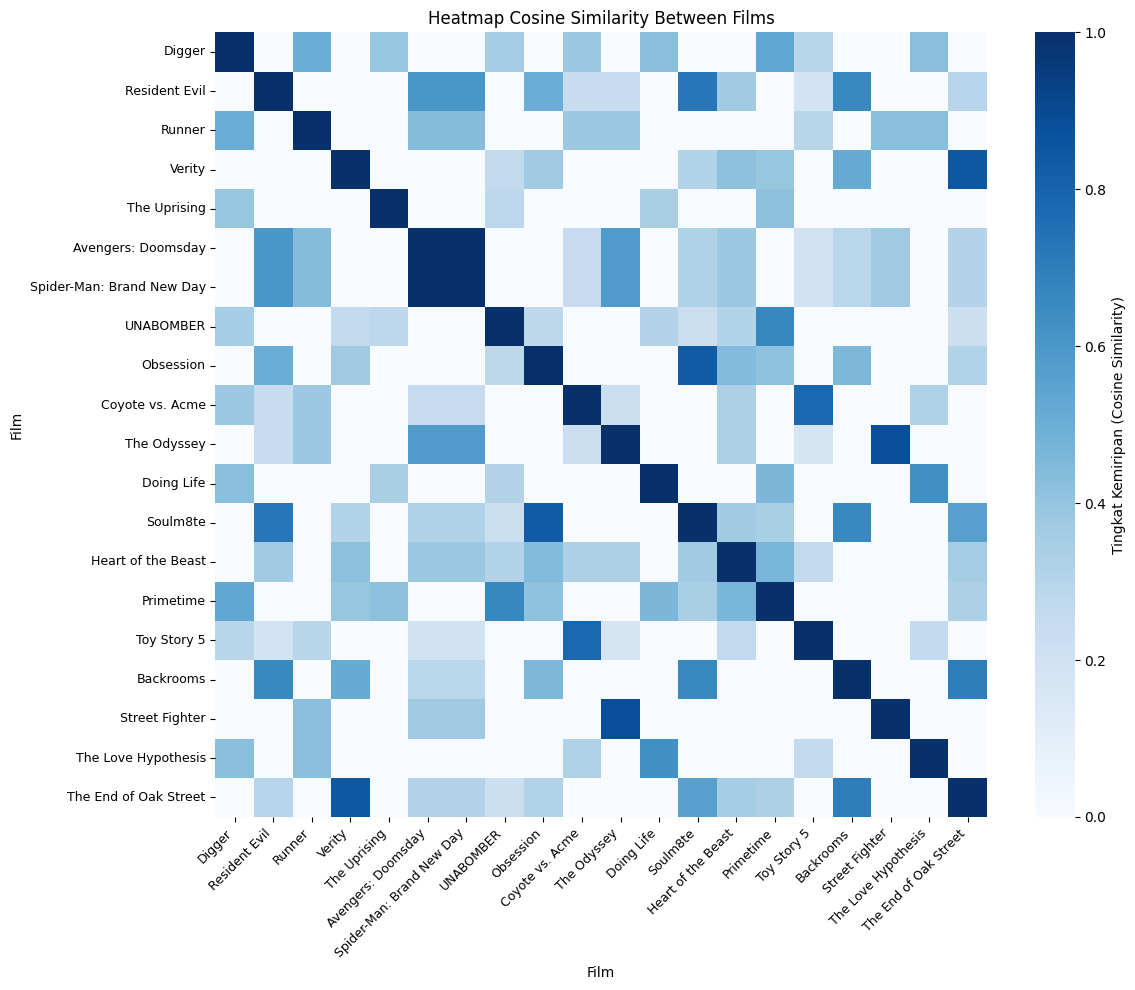

In [225]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    similarity,
    annot=False,
    fmt='.2f',
    cmap='Blues',
    xticklabels=df['Title'],
    yticklabels=df['Title'],
    cbar_kws={'label': 'Tingkat Kemiripan (Cosine Similarity)'},
)

plt.title('Heatmap Cosine Similarity Between Films')
plt.xlabel('Film')
plt.ylabel('Film')

plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

In [226]:
pca = PCA(n_components=2)
coords = pca.fit_transform(tfidf_matrix)

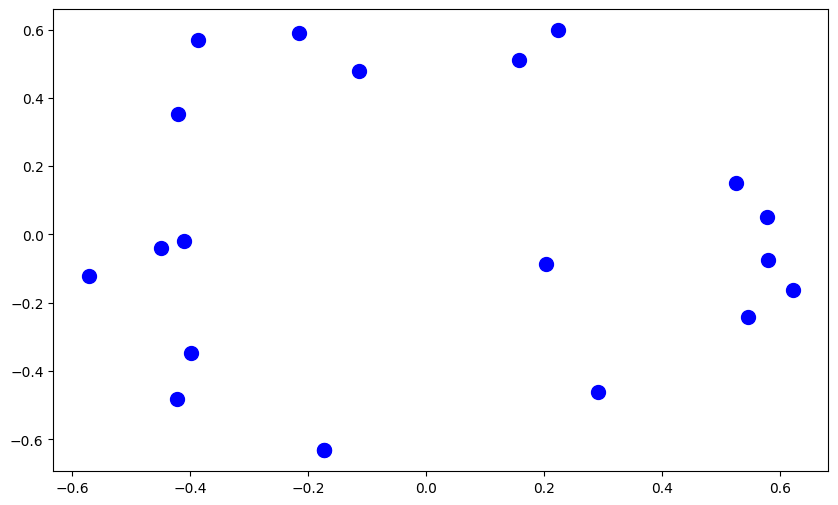

In [227]:
plt.figure(figsize=(10, 6))
plt.scatter(coords[:, 0], coords[:, 1], color='blue', s=100)

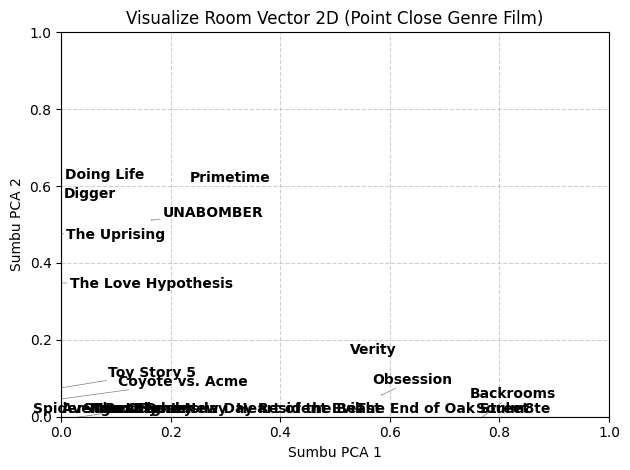

In [228]:
texts = []
for i, title in enumerate(df['Title']):
  t = plt.text(
      coords[i, 0],
      coords[i, 1],
      title,
      fontsize=10,
      fontweight='bold',
  )
  texts.append(t)

adjust_text(
    texts,
    arrowprops=dict(
        arrowstyle = '->', color='gray', lw=0.5
    )
)

plt.title('Visualize Room Vector 2D (Point Close Genre Film)')
plt.xlabel('Sumbu PCA 1')
plt.ylabel('Sumbu PCA 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='grey', linewidth=0.8)
plt.axvline(0, color='grey', linewidth=0.8)
plt.tight_layout()
plt.show()

In [229]:
def recommend(title):
  idx = df[df['Title'] == title].index[0]
  scores = list(enumerate(similarity[idx]))
  scores = sorted(scores, key=lambda x: x[1], reverse=True)
  for i in scores[1:3]:
    print(df['Title'][i[0]])

In [230]:
recommend('Street Fighter')

The Odyssey
Runner
